## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


Survival is 24.2% with the pump and 25.2% without (conservative), so the point estimate of the ATE is -0.01 (so around one percentage point lower survival with the pump). Thus, I would rather note get the pump, for it shows no survival benefit, and is an invasive procedure.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [5]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

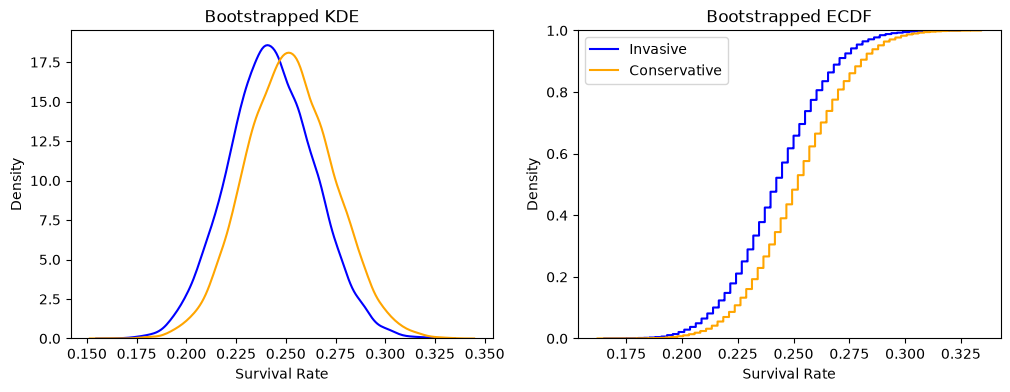

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

The two distributions overlap; both are centered near 24-25% survival with very similar spread, and the conservative curve sits slightly to the right of the invasive curve - there does not appear to be clear seperation between the groups.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

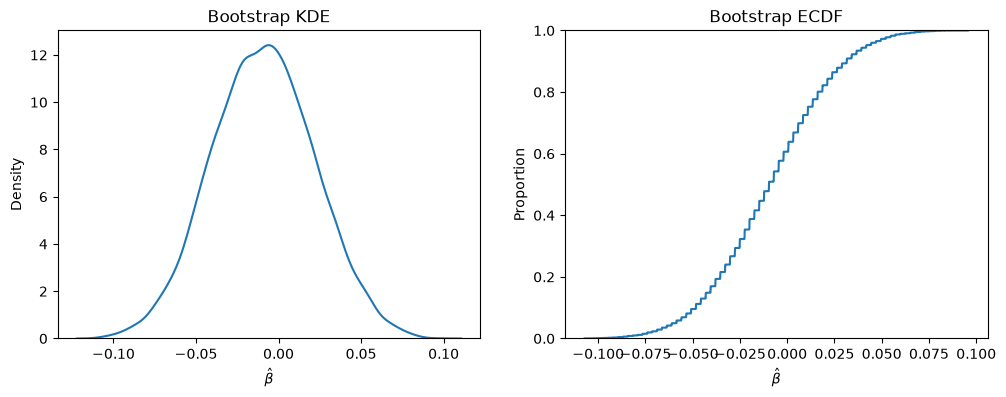

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Yes, it does, and it's centered near 0.01. Plausible values range from around -0.10 to 0.08.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [8]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05862309  0.04184003]
95% CI: [-0.0688787   0.05210956]
99% CI: [-0.08686697  0.07009779]


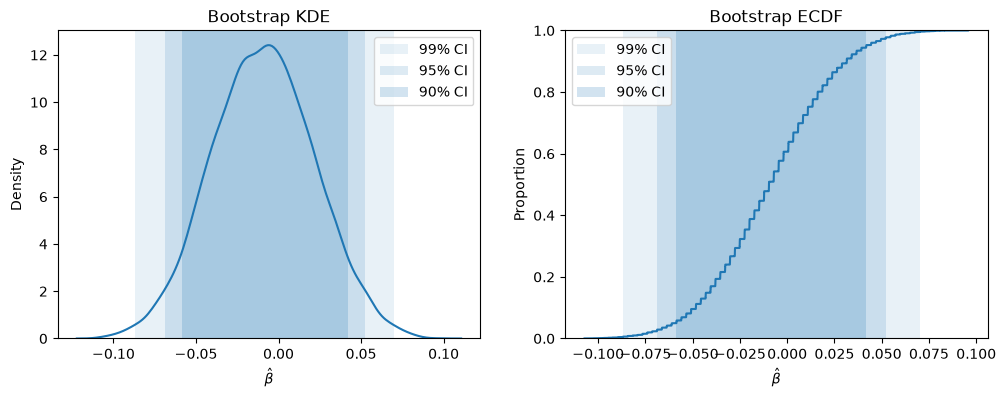

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

Zero is inside all the intervals, so all three levels we fail to reject the null hypothesis that the effect size is zero.

**6.** What have we learned about inserting balloons into hearts?

Inserting balloon pumps did not improve survival in this trial, for the point estimate is slightly negative, and every confidence interval contains zero. The data rule out large effects in both directions, but they cannot tell a small benefit apart from a small harm, and since the procedure is invasive and shows no demonstrated benefit, the evidence does not support using it.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

1. Load the data and cross tabulate outcomes

In [19]:
df = pd.read_csv('./data/diabetes.csv')

df['Success'] = (df['outcome'] == 'success')*1

print(pd.crosstab(df['treatment'], df['outcome']), '\n')

print('Met:', np.round(df.loc[ df['treatment'] == 'met', 'Success'].mean(), 3))
print('Rosi:', np.round(df.loc[ df['treatment'] == 'rosi', 'Success'].mean(), 3))
print('Lifestyle:', np.round(df.loc[ df['treatment'] == 'lifestyle', 'Success'].mean(), 3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Met: 0.483
Rosi: 0.614
Lifestyle: 0.534


Success rates are met 48.3%, lifestyle 53.4%, and rosi 61.4%.

2. Boostrap

In [20]:
## Bootstrapping:
R = 10_000

df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi',:]
df_life = df.loc[ df['treatment'] == 'lifestyle',:]

outcome_met = []
outcome_rosi = []
outcome_life = []

for t in range(R):
    ## Resample:
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_life_t = df_life.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    omt = df_met_t['Success'].mean() 
    ort = df_rosi_t['Success'].mean()     
    olt = df_life_t['Success'].mean() 


    
    ## Store results:
    outcome_met.append(omt) # Save new value
    outcome_rosi.append(ort) # Save new value
    outcome_life.append(olt)

3. Plot densities

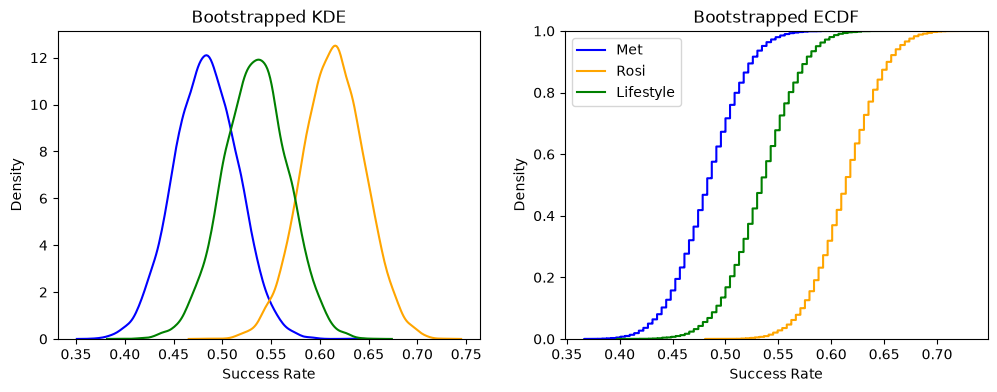

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Met', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosi', color='orange', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Met', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosi', color='orange', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Density')

plt.legend()
plt.savefig('./src/diabetes_arms.png')
plt.show()

The three arms line up in a clear order, with met < lifestyle < rosi, and all three have similar spread. Rosi's distribution is mostly separated from met's, and lifestyle sits in between and overlaps substantially with both. In the ECDF, rosi's curve lies entirely to the right of the met curve.

4. Treatment effect plots

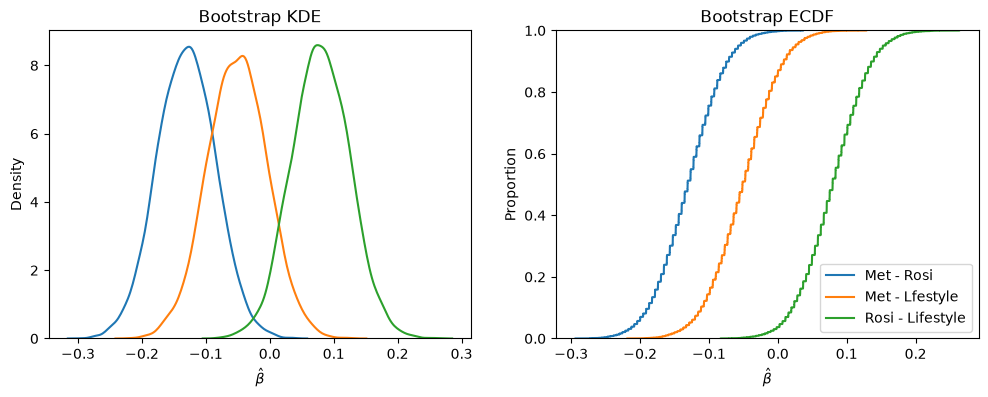

In [26]:
ate_mr = np.array(outcome_met) - np.array(outcome_rosi)
ate_ml = np.array(outcome_met) - np.array(outcome_life)
ate_rl = np.array(outcome_rosi) - np.array(outcome_life)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_mr, label='Met - Rosi', ax=ax[0])
sns.kdeplot(ate_ml, label='Met - Lifestyle', ax=ax[0])
sns.kdeplot(ate_rl, label='Rosi - Lifestyle', ax=ax[0])

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

sns.ecdfplot(ate_mr, label='Met - Rosi', ax=ax[1])
sns.ecdfplot(ate_ml, label='Met - Lfestyle', ax=ax[1])
sns.ecdfplot(ate_rl, label='Rosi - Lifestyle', ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.legend()
plt.savefig('./src/diabetes_ate.png')
plt.show()


5. Compute CIs

In [27]:
for name, ate in [('Met - Rosi', ate_mr), ('Met - Lifestyle', ate_ml), ('Rosi - Lifestyle', ate_rl)]:
    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])


    print(name)
    print(f"90% CI: {ci90}")
    print(f"95% CI: {ci95}")
    print(f"99% CI: {ci99}")

Met - Rosi
90% CI: [-0.20414108 -0.05775307]
95% CI: [-0.221197   -0.04071657]
99% CI: [-0.24715147 -0.01069215]
Met - Lifestyle
90% CI: [-0.12853669  0.02582523]
95% CI: [-0.14168877  0.03897823]
99% CI: [-0.17145612  0.06881834]
Rosi - Lifestyle
90% CI: [0.00673031 0.15247056]
95% CI: [-0.01019772  0.1695279 ]
99% CI: [-0.04029575  0.19949754]


For met - rosi, all three intervals lie below 0, so this difference is statistically significant at every level. For met - lifestyle, all intervals contain zero, so this difference is not significant. For rosi - lifestyle, the 90% interval lies above zero, but the other two contain zero, so this difference is only siginificant at the 90% level.

Given all this, rosi seems the most effect, for it had the highest success rate at around 0.614, and it beats met at each level, and beats lifestyle at the 90% level.

### Report

Purpose / methods: This review evaluates a randomzied controlled trial of three treatments intended to reduce progression from pre-diabetes to full diabetes, including metformin (met), rosiglitazone (rosi), and lifestyle adjustment (lifestyle). Each participant's outcome was recorded as success or failure. Because treatment was randomly assigned, the difference in success rates between two arms estimates the average treatment effect (ATE) of one treatment relative to the other. To quanitfy uncertainty, we bootstrapped each arm's success rate 10,000 times, resampling within arms, and computed percentile confidence intervals (CIs) for each paiwise difference.

Observed outcomes: Rosi had the highest success rate, lifestyle was in the middle, and met had the lowest. Figure 1 shows the bootstrap distributions of each arm's success rate. Met and rosi overlapp only a little, and lifestyle overlaps with both.

| Arm | Successes | Failures | Success rate |
|---|---|---|---|
| Met | 112 | 120 | 0.483 |
| Lifestyle | 125 | 109 | 0.534 |
| Rosi | 143 | 90 | 0.614 |

*Table 1. Outcomes by treatment arm*

<img src="./src/diabetes_arms.png">

*Figure 1. Bootstrap densities (left) and ECDFs (right) of each arm's success rate.*

Pairwise comparisons: Table 2 and Figure 2 summarize the three pairwise comparisons. All three met - rosi intervals lie below zero, so rosi's advantage over met is statistically significant. The level 90% rosi - lifestyle interval lies above zero, but the 95% and 99% intervals contain zero, so rosi's advantage over lifestyle is only significant at the 90% level. All three met - lifestyle intervals contain zero, so the trial shows no significant difference between those two treatments.

| Comparison | 90% CI | 95% CI | 99% CI |
|---|---|---|---|
| Met − Rosi | (−0.204, −0.058) | (−0.221, −0.041) | (−0.247, −0.011) |
| Met − Lifestyle | (−0.129, 0.026) | (−0.142, 0.039) | (−0.171, 0.069) |
| Rosi − Lifestyle | (0.007, 0.152) | (−0.010, 0.170) | (−0.040, 0.199) |

*Table 2. Percentile boostrap CIs for the difference in success rates.*

<img src="./src/diabetes_ate.png">

*Figure 2. Bootstrap densities (left) and ECDFs (right) of the pairwise differences in success rate.*

Conclusions: The trial gives strong evidence that rosi is more effective than met. It gives weaker evidence, at the 90% level, that rosi is more effective than lifestyle adjustment. It shows no significant difference betweeen met and lifestyle adjustment. These conclusions cover only the recorded success/failure outcome. The data contain no other outcomes that a decision to adopt a treatment would also need to consider.
